# Demo 1 Linear Regression and Fitting

Lecture slide 19. Explore how data, a model, a loss, and optimization fit together.

**How to use in Google Colab**
1. Upload this `.ipynb` using **File → Upload notebook**.
2. Select **Runtime → Run all**. A CPU runtime is sufficient.
3. Read the default figures, then move the sliders. Release a slider to redraw.

All figures and controls use English. All datasets are generated locally with fixed random seeds.
Changing a control never requires uploading a file. If a widget is unavailable, edit the
arguments of the corresponding `..._view(...)` call and rerun that cell.

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from scipy.special import expit
from IPython.display import display
import ipywidgets as widgets
try:
    from google.colab import output
    output.enable_custom_widget_manager()
except ImportError:
    pass  # Also runs in a standard Jupyter environment.

BLUE, ORANGE, TEAL, NAVY = '#1479e8', '#ff8a20', '#079f9f', '#10264e'
COLORS = [BLUE, ORANGE, TEAL]
REGIONS = ListedColormap(['#dfedff', '#ffe8d5', '#d7f3ef'])
plt.rcParams.update({'figure.dpi':110, 'font.size':11, 'axes.spines.top':False,
                     'axes.spines.right':False, 'axes.labelcolor':NAVY,
                     'axes.titlesize':12, 'figure.constrained_layout.use':True})

def slider(value, low, high, step, label):
    return widgets.FloatSlider(value=value, min=low, max=high, step=step,
                               description=label, continuous_update=False,
                               style={'description_width':'initial'})

def integer(value, low, high, label, step=1):
    return widgets.IntSlider(value=value, min=low, max=high, step=step,
                             description=label, continuous_update=False,
                             style={'description_width':'initial'})

def controls(fn, **kwargs):
    # Release the slider to redraw. A normal static example is shown above each control.
    panel = widgets.interactive(fn, **kwargs)
    display(panel)
    return panel

def class_points(ax, X, y, alpha=1, size=26):
    for k in np.unique(y):
        ax.scatter(*X[y==k].T, c=COLORS[int(k)], s=size, alpha=alpha,
                   edgecolors='white', linewidths=.4, label=['P','Q','R'][int(k)])

def mesh(X, n=150, pad=.7):
    lo, hi = X.min(axis=0)-pad, X.max(axis=0)+pad
    gx, gy = np.meshgrid(np.linspace(lo[0],hi[0],n), np.linspace(lo[1],hi[1],n))
    return gx, gy, np.c_[gx.ravel(),gy.ravel()]

print('Ready. CPU is sufficient. No external datasets are required.')

Ready. CPU is sufficient. No external datasets are required.


## 1 Move the line and measure its loss
The model is $\hat y=ax+b$ and $L=\frac1N\sum_i(\hat y_i-y_i)^2$.
The vertical segments are residuals at the **same input** $x_i$.
The contour plot lives in **parameter space** $(a,b)$, not data space $(x,y)$.

Try to minimize the MSE manually. Then increase the outlier offset and observe how the
least-squares line moves. The noise pattern stays fixed when you change its amplitude.

Best fit: a=1.297, b=0.578, MSE=0.178


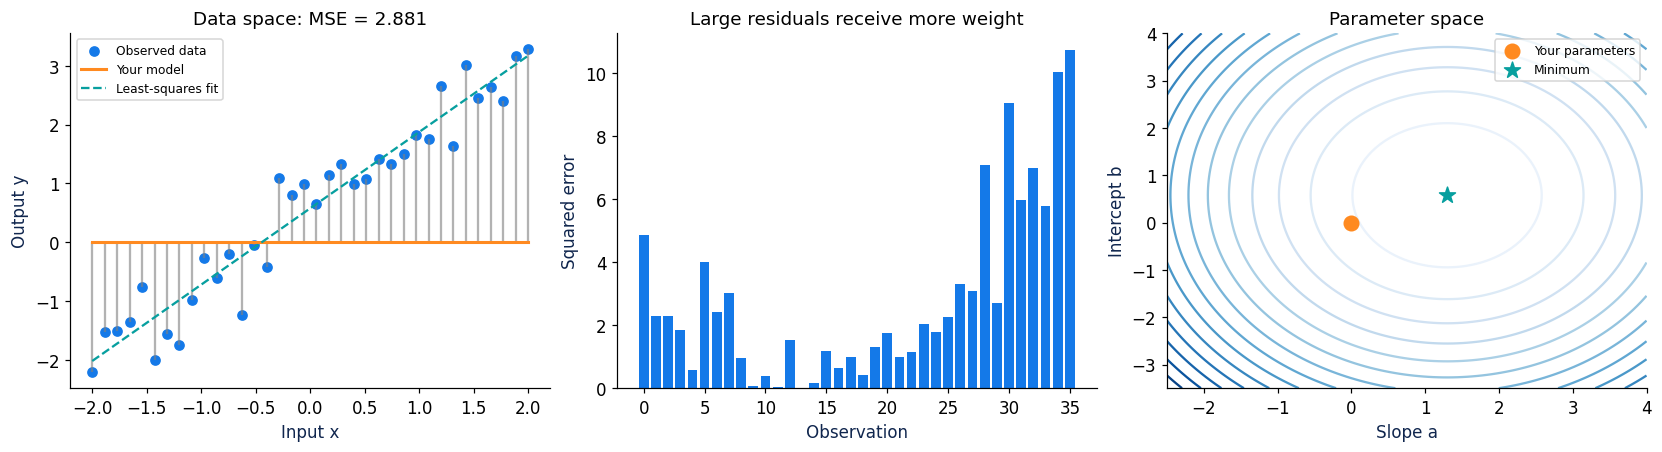

In [5]:
def regression_data(noise=.5, outlier=0):
    x = np.linspace(-2,2,36)
    y = 1.4*x + .6 + noise*np.random.default_rng(12).normal(size=len(x))
    y[-5] += outlier
    return x,y

def regression_view(a=0., b=0., noise=.5, outlier=0.):
    x,y=regression_data(noise,outlier)
    D=np.c_[x,np.ones(len(x))]
    best=np.linalg.lstsq(D,y,rcond=None)[0]  # Stable least squares; no matrix inverse.
    pred=a*x+b; errors=pred-y; loss=np.mean(errors**2)
    fig,axs=plt.subplots(1,3,figsize=(15,4))
    axs[0].scatter(x,y,c=BLUE,label='Observed data')
    axs[0].vlines(x,y,pred,color='gray',alpha=.6)
    axs[0].plot(x,pred,c=ORANGE,lw=2,label='Your model')
    axs[0].plot(x,D@best,c=TEAL,ls='--',label='Least-squares fit')
    axs[0].set(xlabel='Input x',ylabel='Output y',title=f'Data space: MSE = {loss:.3f}')
    axs[0].legend(fontsize=8)
    axs[1].bar(np.arange(len(x)),errors**2,color=BLUE)
    axs[1].set(xlabel='Observation',ylabel='Squared error',title='Large residuals receive more weight')
    ar=np.linspace(-2.5,4,100);br=np.linspace(-3.5,4,100)
    aa,bb=np.meshgrid(ar,br)
    zz=np.mean((aa[...,None]*x+bb[...,None]-y)**2,axis=-1)
    axs[2].contour(aa,bb,zz,levels=15,cmap='Blues')
    axs[2].scatter([a],[b],s=90,c=ORANGE,label='Your parameters',zorder=5)
    axs[2].scatter(*best,s=120,c=TEAL,marker='*',label='Minimum',zorder=5)
    axs[2].set(xlabel='Slope a',ylabel='Intercept b',title='Parameter space')
    axs[2].legend(fontsize=8)
    plt.show()
    print(f'Best fit: a={best[0]:.3f}, b={best[1]:.3f}, MSE={np.mean((D@best-y)**2):.3f}')

regression_view()

Best fit: a=1.297, b=0.578, MSE=0.178


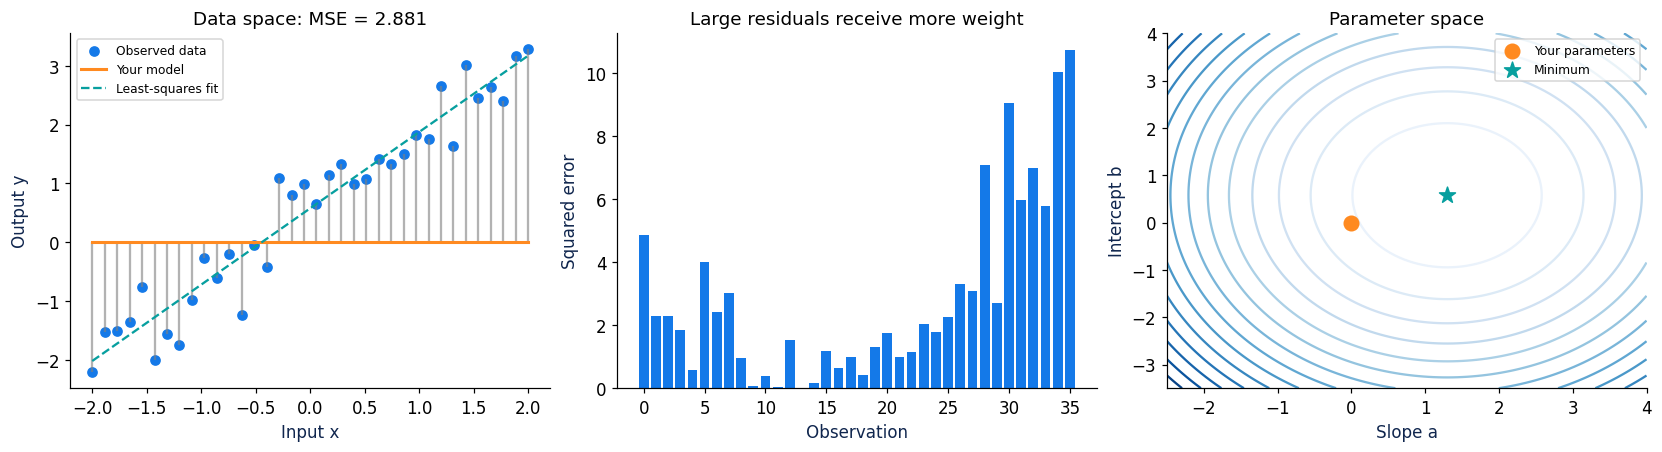

interactive(children=(FloatSlider(value=0.0, continuous_update=False, description='Slope a', max=4.0, min=-2.0…

In [6]:
line_controls=controls(regression_view,
    a=slider(0,-2,4,.1,'Slope a'), b=slider(0,-3,4,.1,'Intercept b'),
    noise=slider(.5,0,1.5,.1,'Noise'), outlier=slider(0,0,10,.5,'Outlier offset'))

## 2 Compare direct fitting and gradient updates
For linear regression, solving the normal equations and minimizing MSE give the same optimum.
We compute that reference using `numpy.linalg.lstsq` rather than explicitly inverting $X^TX$.

Gradient descent uses $\theta_{k+1}=\theta_k-\eta\nabla L_B(\theta_k)$, where $L_B$
is the **mean** squared error over the chosen batch.

- Batch: one update per epoch, using all $N$ observations.
- Mini-batch: several updates per epoch, here with batch size 6.
- SGD: one observation per update, hence $N$ updates per epoch.

All methods start at the same parameters and use a constant learning rate. Mini-batch and SGD
shuffle without replacement each epoch. Compare by **data passes** and also by **update count**;
one update does not have the same computational cost for all methods.

Batch     : updates=  15, passes=15.0, MSE=0.21889
Mini-batch: updates=  90, passes=15.0, MSE=0.17857
SGD       : updates= 540, passes=15.0, MSE=0.20527


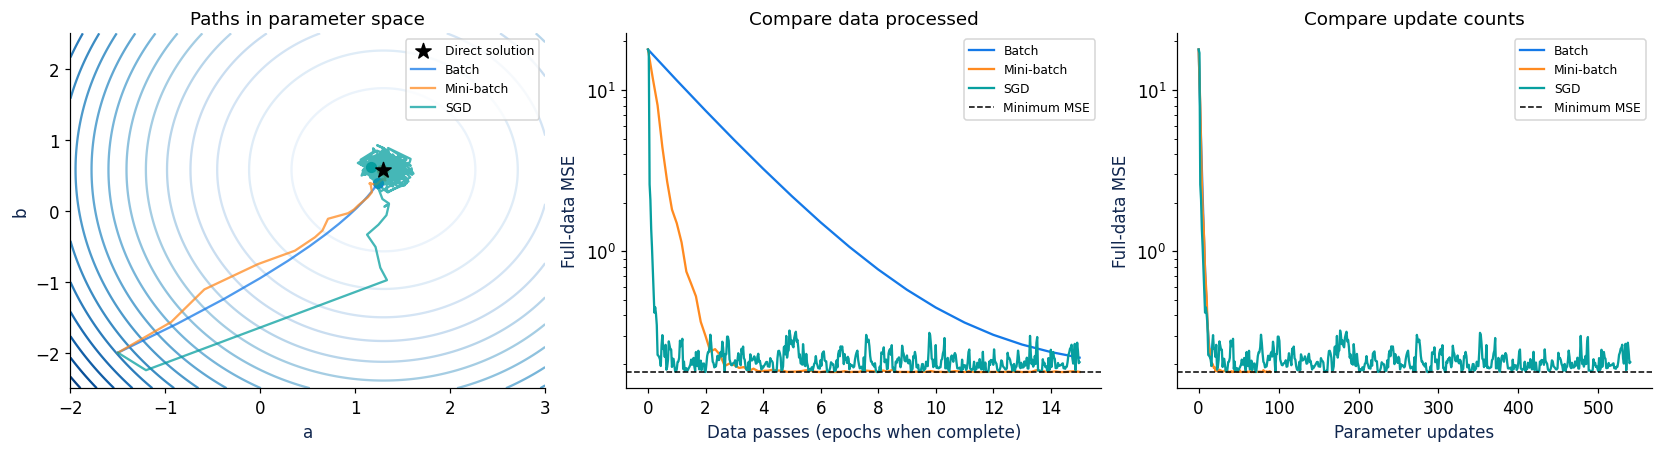

In [8]:
x_opt,y_opt=regression_data(.5,0)
D_opt=np.c_[x_opt,np.ones(len(x_opt))]
theta_star=np.linalg.lstsq(D_opt,y_opt,rcond=None)[0]

def optimize_path(method, eta, epochs):
    rng=np.random.default_rng(8);theta=np.array([-1.5,-2.])
    path=[theta.copy()];loss=[np.mean((D_opt@theta-y_opt)**2)];passes=[0.]
    seen=0;size={'Batch':len(x_opt),'Mini-batch':6,'SGD':1}[method]
    diverged=False
    for ep in range(epochs):
        order=rng.permutation(len(x_opt))
        for start in range(0,len(order),size):
            idx=order[start:start+size]
            grad=2*D_opt[idx].T@(D_opt[idx]@theta-y_opt[idx])/len(idx)
            candidate=theta-eta*grad
            if not np.all(np.isfinite(candidate)) or np.linalg.norm(candidate)>1e5:
                diverged=True;break
            theta=candidate;seen+=len(idx)
            path.append(theta.copy());loss.append(np.mean((D_opt@theta-y_opt)**2))
            passes.append(seen/len(x_opt))
        if diverged:break
    return np.array(path),np.array(loss),np.array(passes),diverged

def optimizer_view(method='Compare all', eta=.08, epochs=15):
    methods=['Batch','Mini-batch','SGD'] if method=='Compare all' else [method]
    fig,axs=plt.subplots(1,3,figsize=(15,4))
    aa,bb=np.meshgrid(np.linspace(-2,3,120),np.linspace(-2.5,2.5,120))
    zz=np.mean((aa[...,None]*x_opt+bb[...,None]-y_opt)**2,axis=-1)
    axs[0].contour(aa,bb,zz,levels=18,cmap='Blues')
    axs[0].scatter(*theta_star,c='black',marker='*',s=110,label='Direct solution',zorder=6)
    best_loss=np.mean((D_opt@theta_star-y_opt)**2)
    for j,m in enumerate(methods):
        path,loss,passes,diverged=optimize_path(m,eta,epochs)
        c=COLORS[['Batch','Mini-batch','SGD'].index(m)]
        axs[0].plot(*path.T,color=c,alpha=.75,label=m)
        axs[0].scatter(*path[-1],c=c,s=40)
        axs[1].plot(passes,loss,c=c,label=m)
        axs[2].plot(np.arange(len(loss)),loss,c=c,label=m)
        print(f'{m:10s}: updates={len(path)-1:4d}, passes={passes[-1]:.1f}, '
              f'MSE={loss[-1]:.5f}'+(' — diverged; reduce the learning rate' if diverged else ''))
    axs[0].set(xlabel='a',ylabel='b',title='Paths in parameter space',xlim=(-2,3),ylim=(-2.5,2.5))
    for ax,xlab in zip(axs[1:],['Data passes (epochs when complete)','Parameter updates']):
        ax.axhline(best_loss,c='black',ls='--',lw=1,label='Minimum MSE')
        ax.set(xlabel=xlab,ylabel='Full-data MSE',yscale='log')
    axs[1].set_title('Compare data processed');axs[2].set_title('Compare update counts')
    for ax in axs:ax.legend(fontsize=8)
    plt.show()

optimizer_view()

Batch     : updates=  15, passes=15.0, MSE=0.21889
Mini-batch: updates=  90, passes=15.0, MSE=0.17857
SGD       : updates= 540, passes=15.0, MSE=0.20527


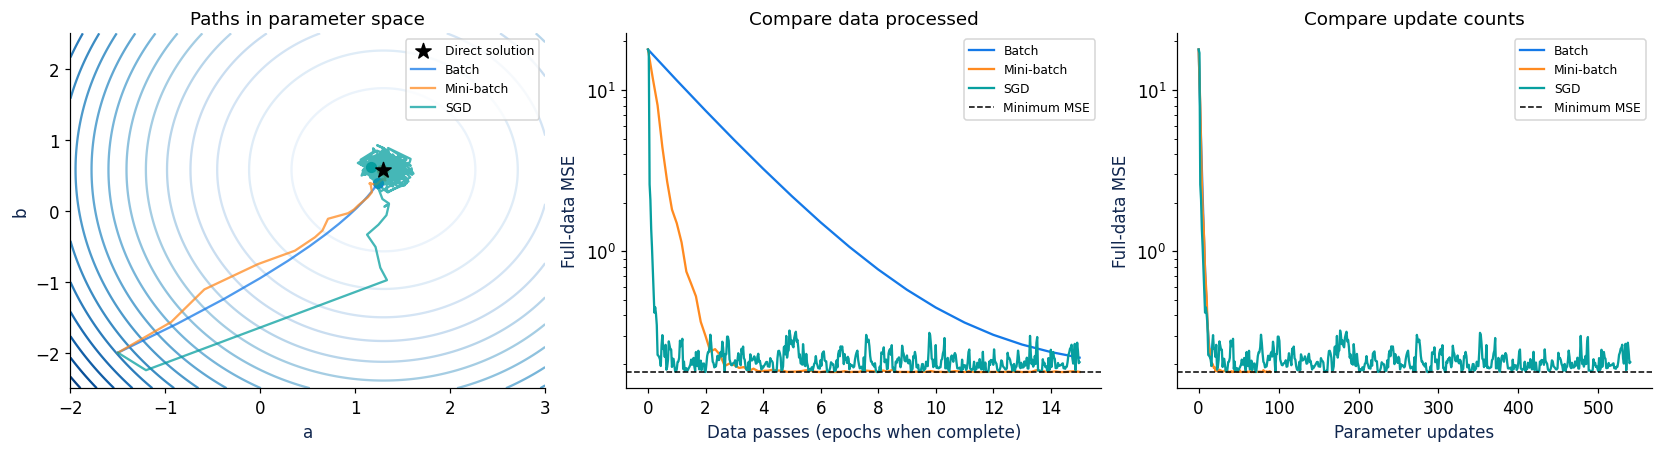

interactive(children=(Dropdown(description='Method', options=('Compare all', 'Batch', 'Mini-batch', 'SGD'), va…

In [9]:
optimizer_controls=controls(optimizer_view,
    method=widgets.Dropdown(options=['Compare all','Batch','Mini-batch','SGD'],value='Compare all',description='Method'),
    eta=slider(.08,.005,1.1,.005,'Learning rate'), epochs=integer(15,1,60,'Epochs'))

## 3 Optional extension Polynomial features and regularization
This section previews the later slides on feature transforms, generalization, and regularization.
The input is mapped to $(x,x^2,\ldots,x^d)$; the model remains **linear in its coefficients**.

We minimize $J=\mathrm{MSE}_{train}+\lambda\sum_jw_j^2$, excluding the intercept.
All powers use the fixed input range $[-1,1]$; L2 regularization depends on the feature representation.
Only training data fit the coefficients. Validation data help choose degree and $\lambda$.
No test set is used for tuning in this demonstration.

Selected model: train MSE=0.0732, validation MSE=5.5384


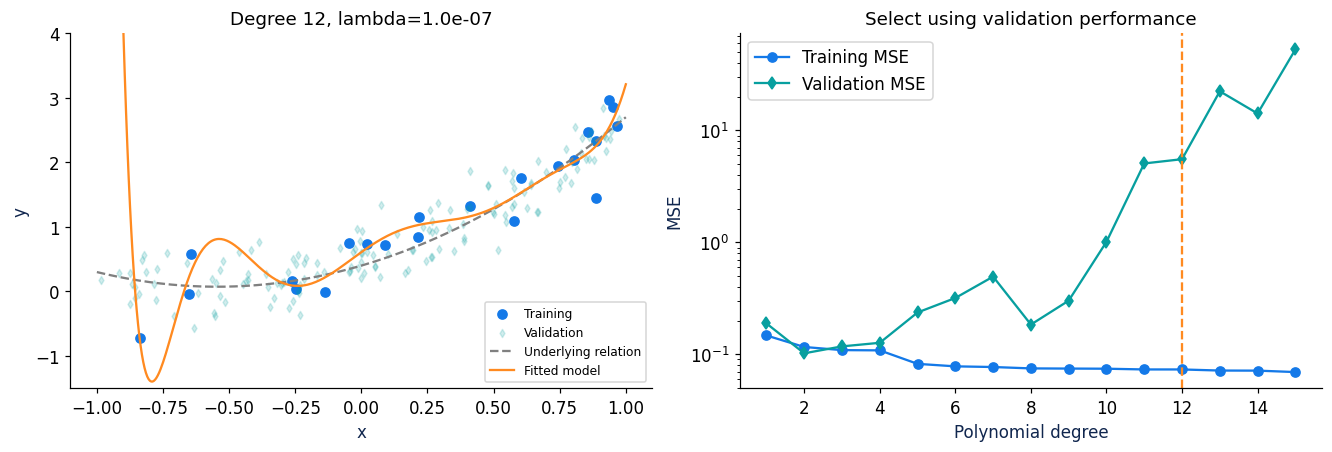

In [11]:
from sklearn.linear_model import Ridge
from sklearn.preprocessing import PolynomialFeatures

rng_poly=np.random.default_rng(4)
xp_train=np.sort(rng_poly.uniform(-1,1,22));xp_val=np.sort(rng_poly.uniform(-1,1,150))
true_fn=lambda x: .4+1.2*x+1.1*x**2
yp_train=true_fn(xp_train)+rng_poly.normal(0,.3,len(xp_train))
yp_val=true_fn(xp_val)+rng_poly.normal(0,.3,len(xp_val))

def fit_poly(degree, lam):
    features=PolynomialFeatures(degree,include_bias=False)
    model=Ridge(alpha=len(xp_train)*lam,fit_intercept=True,solver='svd')
    model.fit(features.fit_transform(xp_train[:,None]),yp_train)
    return features,model

def polynomial_view(degree=12, log_lambda=-7.):
    lam=10.**log_lambda;features,model=fit_poly(degree,lam)
    xx=np.linspace(-1,1,400);pred=model.predict(features.transform(xx[:,None]))
    fig,axs=plt.subplots(1,2,figsize=(12,4))
    axs[0].scatter(xp_train,yp_train,c=BLUE,label='Training')
    axs[0].scatter(xp_val,yp_val,c=TEAL,marker='d',alpha=.18,s=14,label='Validation')
    axs[0].plot(xx,true_fn(xx),c='gray',ls='--',label='Underlying relation')
    axs[0].plot(xx,pred,c=ORANGE,label='Fitted model')
    axs[0].set(xlabel='x',ylabel='y',ylim=(-1.5,4),title=f'Degree {degree}, lambda={lam:.1e}')
    axs[0].legend(fontsize=8)
    tr,va=[],[]
    for deg in range(1,16):
        f,m=fit_poly(deg,lam)
        tr.append(np.mean((m.predict(f.transform(xp_train[:,None]))-yp_train)**2))
        va.append(np.mean((m.predict(f.transform(xp_val[:,None]))-yp_val)**2))
    axs[1].plot(range(1,16),tr,'o-',c=BLUE,label='Training MSE')
    axs[1].plot(range(1,16),va,'d-',c=TEAL,label='Validation MSE')
    axs[1].axvline(degree,color=ORANGE,ls='--')
    axs[1].set(xlabel='Polynomial degree',ylabel='MSE',yscale='log',title='Select using validation performance')
    axs[1].legend();plt.show()
    print(f'Selected model: train MSE={tr[degree-1]:.4f}, validation MSE={va[degree-1]:.4f}')

polynomial_view()

Selected model: train MSE=0.0732, validation MSE=5.5384


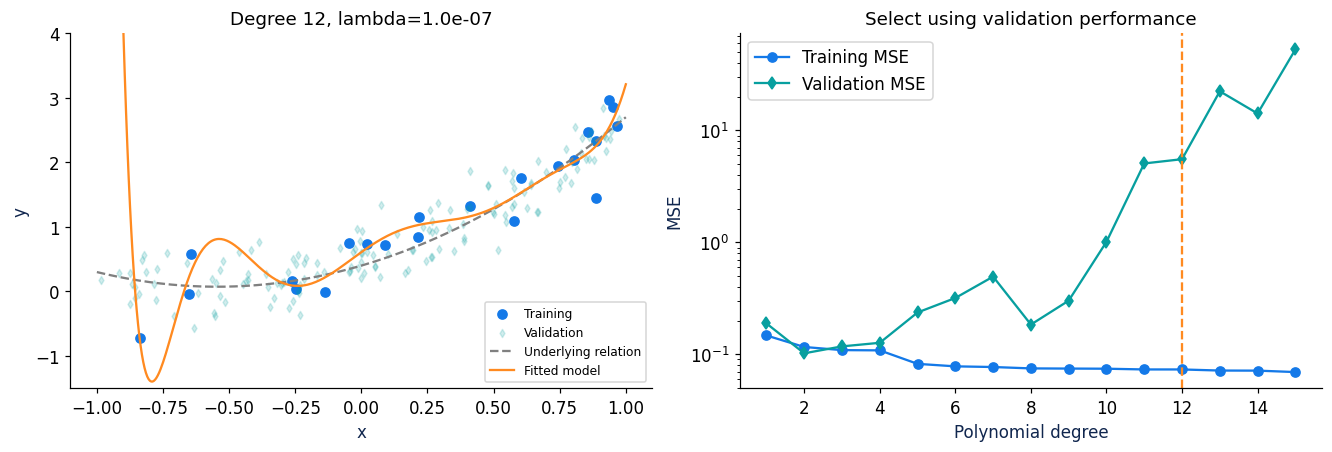

interactive(children=(IntSlider(value=12, continuous_update=False, description='Degree', max=15, min=1, style=…

In [12]:
polynomial_controls=controls(polynomial_view,
    degree=integer(12,1,15,'Degree'),log_lambda=slider(-7,-8,2,.5,'log10(lambda)'))

## Check your understanding
1. Why do the data plot and the loss contour have different axes?
2. Why can SGD's full-data MSE increase after an individual update?
3. Is one epoch always one update?
4. Does a higher polynomial degree always improve validation performance?

**Documentation:** [NumPy least squares](https://numpy.org/doc/stable/reference/generated/numpy.linalg.lstsq.html),
[Ridge](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Ridge.html).